# NETDEFY — Notebook 01: Dataset Overview & Chronological Topology

**Project:** NETDEFY — Network Defense Intelligence  
**Notebook:** `notebooks/01_dataset_overview.ipynb`  
**Purpose:** Dataset structure, forensic file dimensions, ground-truth label distributions, day-wise operational sequencing, and benchmark allocation.  
**Historical Provenance:** Phase 2 Forensic Inspection (`reports/dataset_forensic_summary.md`, `reports/label_distribution.md`, `reports/temporal_distribution.md`) and Phase 3.2 Benchmark Architecture (`reports/PHASE3_2_BENCHMARK_CONSTRUCTION.md`).  
**Provenance Disclosure:**
- File-level dimensions, nulls, and duplicate statistics are recovered directly from the verified Phase 2 forensic manifest (`reports/dataset_forensic_summary.json`).
- Day-wise operational distributions are dynamically aggregated from the forensic manifest's per-file records.
- Benchmark partition dimensions and checksums are computed directly from the frozen benchmark metadata (`data/benchmark/v1/metadata/benchmark_manifest.json`).

---

### Research Questions
1. What is the physical volume, record count, and schema composition of the official CICIDS2017 dataset (`MachineLearningCVE`)?
2. What is the global distribution of network flows between benign baseline traffic and malicious attacks?
3. What is the degree of class imbalance across the 15 ground-truth traffic categories?
4. How is traffic partitioned chronologically across capture days (Monday through Friday), and why is day-level temporal separation required?
5. How was the official 200,000-record NETDEFY benchmark (`data/benchmark/v1/`) constructed from the full 2.83M-record corpus?


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Repository-aware path resolution
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
reports_dir = project_root / "reports"
benchmark_dir = project_root / "data" / "benchmark" / "v1"

# Styling configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "axes.edgecolor": "#cccccc",
        "axes.linewidth": 0.8,
        "grid.color": "#eaeaea",
        "grid.linestyle": "--",
    }
)

print(f"Project root resolved to: {project_root}")
print(f"Reports directory exists: {reports_dir.exists()}")
print(f"Benchmark v1 directory exists: {benchmark_dir.exists()}")

Project root resolved to: /Users/nitinkumar/Documents/Netdefy
Reports directory exists: True
Benchmark v1 directory exists: True


## 1. Dataset Acquisition & Physical Topology

The CICIDS2017 dataset was acquired from the University of New Brunswick (UNB) as part of Phase 2.
The official machine learning release (`MachineLearningCVE`) consists of 8 CSV files generated by CICFlowMeter.

We load the forensic manifest generated during Phase 2 (`reports/dataset_forensic_summary.json`) to inspect file sizes, record counts, and schema uniformity.


In [2]:
with open(reports_dir / "dataset_forensic_summary.json") as f:
    forensic_data = json.load(f)

file_records = []
for fr in forensic_data["file_reports"]:
    file_records.append(
        {
            "Filename": fr["filename"],
            "Size (MB)": round(fr["file_size_bytes"] / (1024 * 1024), 2),
            "Rows": fr["total_rows"],
            "Cols": fr["total_columns"],
            "Benign Flows": fr["benign_count"],
            "Attack Flows": fr["attack_count"],
            "Attack Share (%)": round(fr["attack_pct"], 2),
            "Intra-File Dups": fr["intra_file_duplicate_rows"],
        }
    )

df_files = pd.DataFrame(file_records).sort_values("Rows", ascending=False).reset_index(drop=True)
print(f"Total Files Analyzed: {len(df_files)}")
print(f"Total Records Across Files: {df_files['Rows'].sum():,}")
print(f"Total Volume: {df_files['Size (MB)'].sum():.2f} MB")
print(f"Schema Uniform Across All Files: {forensic_data['schema_is_consistent']}")

display_cols = [
    "Filename",
    "Size (MB)",
    "Rows",
    "Cols",
    "Benign Flows",
    "Attack Flows",
    "Attack Share (%)",
]
print(df_files[display_cols].to_string(index=False))

Total Files Analyzed: 8
Total Records Across Files: 2,830,743
Total Volume: 843.66 MB
Schema Uniform Across All Files: True
                                                   Filename  Size (MB)   Rows  Cols  Benign Flows  Attack Flows  Attack Share (%)
                       Wednesday-workingHours.pcap_ISCX.csv     214.74 692703    79        440031        252672             36.48
                          Monday-WorkingHours.pcap_ISCX.csv     168.73 529918    79        529918             0              0.00
                         Tuesday-WorkingHours.pcap_ISCX.csv     128.82 445909    79        432074         13835              3.10
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv      79.25 288602    79        288566            36              0.01
       Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv      73.34 286467    79        127537        158930             55.48
           Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv      73.55 225745    79         9771

<string>:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


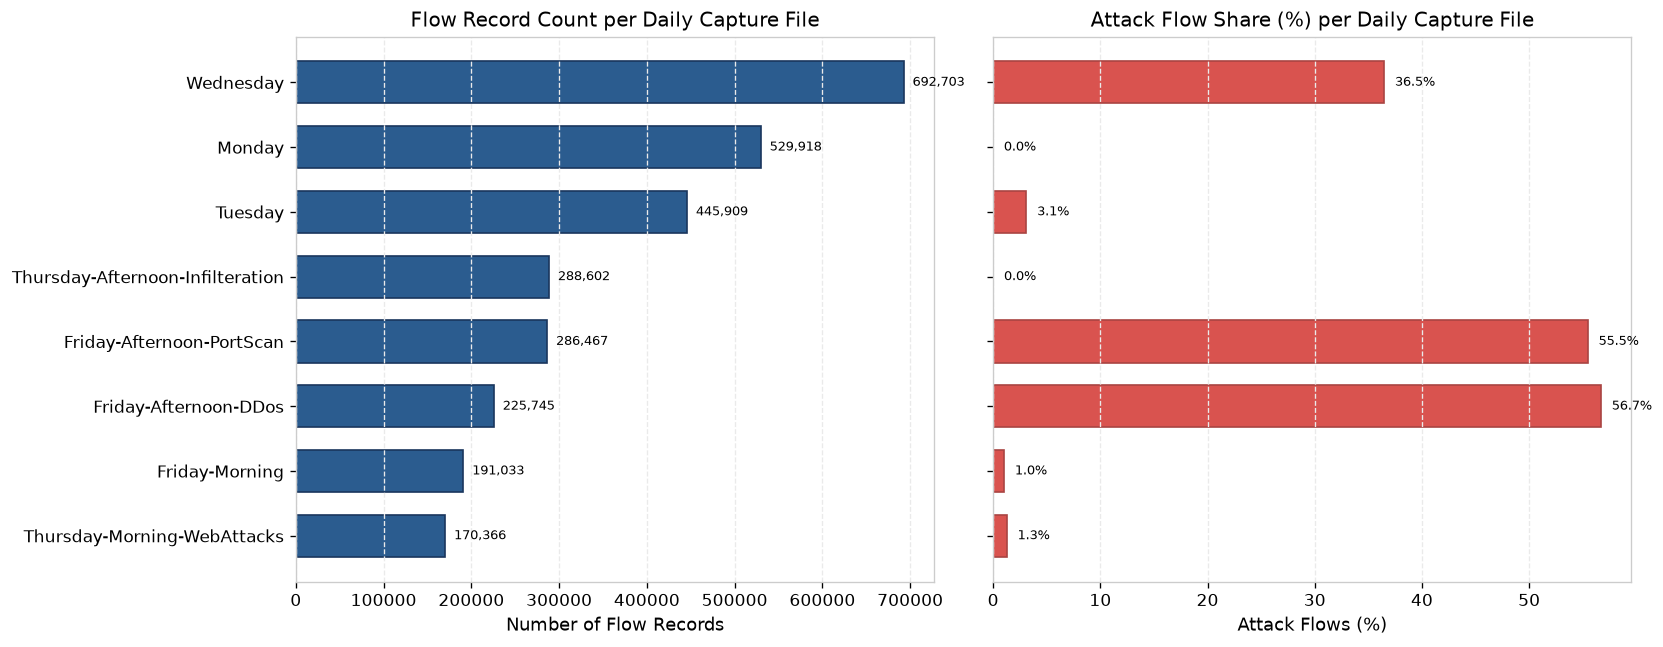

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

short_names = [
    fn.replace(".pcap_ISCX.csv", "").replace("-WorkingHours", "").replace("-workingHours", "")
    for fn in df_files["Filename"]
]
y_pos = np.arange(len(df_files))

# Plot 1: Row Counts
bars1 = ax1.barh(y_pos, df_files["Rows"], color="#2b5c8f", edgecolor="#1a365d", height=0.65)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(short_names)
ax1.invert_yaxis()
ax1.set_xlabel("Number of Flow Records")
ax1.set_title("Flow Record Count per Daily Capture File")
ax1.grid(True, axis="x")
for bar in bars1:
    width = bar.get_width()
    ax1.text(
        width + 10000,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontsize=8,
    )

# Plot 2: Attack Share
bars2 = ax2.barh(
    y_pos, df_files["Attack Share (%)"], color="#d9534f", edgecolor="#a94442", height=0.65
)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])
ax2.invert_yaxis()
ax2.set_xlabel("Attack Flows (%)")
ax2.set_title("Attack Flow Share (%) per Daily Capture File")
ax2.grid(True, axis="x")
for bar in bars2:
    width = bar.get_width()
    ax2.text(
        width + 1, bar.get_y() + bar.get_height() / 2, f"{width:.1f}%", va="center", fontsize=8
    )

plt.tight_layout()
plt.show()

### Observations on Dataset Topology
1. **Total Flow Volume:** The corpus comprises exactly **2,830,743 flows** across 8 capture files totaling **843.66 MB**.
2. **Schema Invariant:** All 8 files contain exactly **79 columns** with identical column headers.
3. **Attack Distribution Variance:** Capture files vary from **0.00% attack flows** on Monday (529,918 pure benign flows) to **56.71% attack flows** on Friday afternoon (DDoS flood).


## 2. Ground-Truth Class Distribution & Severe Class Imbalance

Next, we inspect the ground-truth label distribution across all 2.83M records (`reports/label_distribution.csv`).
We evaluate the severe class imbalance inherent to network intrusion telemetry.


In [4]:
df_labels = pd.read_csv(reports_dir / "label_distribution.csv")
total_flows = df_labels["Count"].sum()
df_labels["Share (%)"] = (df_labels["Count"] / total_flows) * 100

benign_count = df_labels.loc[df_labels["Label"] == "BENIGN", "Count"].iloc[0]
attack_count = total_flows - benign_count

print(f"Total Flows: {total_flows:,}")
print(f"Total Benign Flows: {benign_count:,} ({benign_count / total_flows * 100:.2f}%)")
print(f"Total Attack Flows: {attack_count:,} ({attack_count / total_flows * 100:.2f}%)")
print(f"Global Benign-to-Attack Ratio: {benign_count / attack_count:.2f} : 1")
print()

# Long-tail imbalance ratio
max_attack = df_labels[df_labels["Label"] != "BENIGN"].iloc[0]
min_attack = df_labels.iloc[-1]
print(
    f"Most Frequent Attack: {max_attack['Label']} with {max_attack['Count']:,} flows ({max_attack['Share (%)']:.2f}%)"
)
print(
    f"Rarest Attack: {min_attack['Label']} with {min_attack['Count']:,} flows ({min_attack['Share (%)']:.4f}%)"
)
print(
    f"Extreme Imbalance (Benign vs {min_attack['Label']}): {int(benign_count / min_attack['Count']):,}:1 ratio"
)
print()
print(df_labels.to_string(index=False))

Total Flows: 2,830,743
Total Benign Flows: 2,273,097 (80.30%)
Total Attack Flows: 557,646 (19.70%)
Global Benign-to-Attack Ratio: 4.08 : 1

Most Frequent Attack: DDoS with 128,027 flows (4.52%)
Rarest Attack: Heartbleed with 11 flows (0.0004%)
Extreme Imbalance (Benign vs Heartbleed): 206,645:1 ratio

                     Label   Count  Percentage  Share (%)
                    BENIGN 2273097   80.300366  80.300366
                      DDoS  128027    4.522735   4.522735
                  PortScan  158930    5.614427   5.614427
                       Bot    1966    0.069452   0.069452
              Infiltration      36    0.001272   0.001272
  Web Attack � Brute Force    1507    0.053237   0.053237
          Web Attack � XSS     652    0.023033   0.023033
Web Attack � Sql Injection      21    0.000742   0.000742
               FTP-Patator    7938    0.280421   0.280421
               SSH-Patator    5897    0.208320   0.208320
             DoS slowloris    5796    0.204752   0.204752
 

<string>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


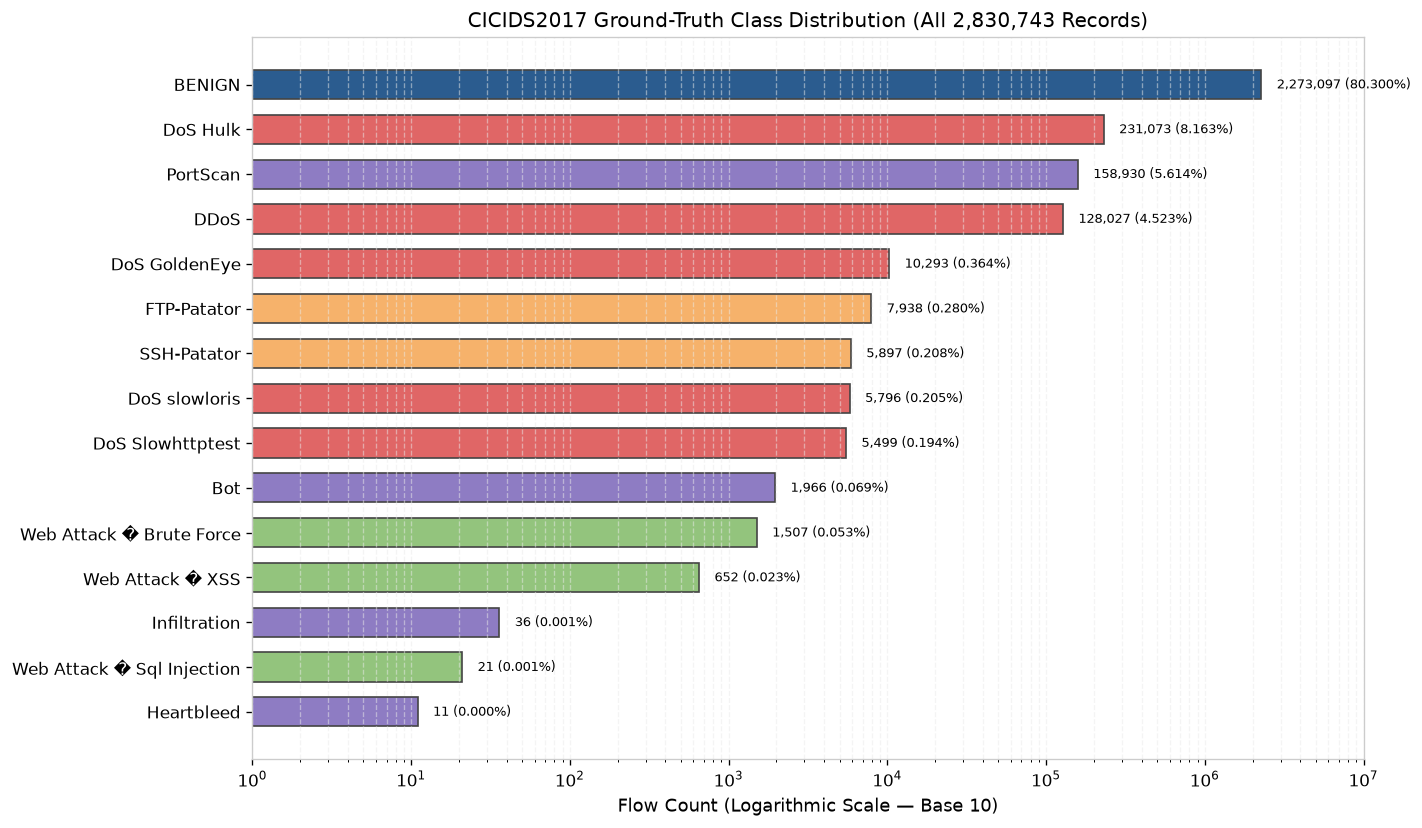

In [5]:
fig, ax = plt.subplots(figsize=(12, 7))

df_plot = df_labels.sort_values("Count", ascending=True).reset_index(drop=True)
colors = [
    "#2b5c8f"
    if label == "BENIGN"
    else "#e06666"
    if "DoS" in label or "DDoS" in label
    else "#f6b26b"
    if "Patator" in label
    else "#93c47d"
    if "Web" in label
    else "#8e7cc3"
    for label in df_plot["Label"]
]

bars = ax.barh(df_plot["Label"], df_plot["Count"], color=colors, edgecolor="#444444", height=0.65)
ax.set_xscale("log")
ax.set_xlabel("Flow Count (Logarithmic Scale — Base 10)")
ax.set_title("CICIDS2017 Ground-Truth Class Distribution (All 2,830,743 Records)")
ax.grid(True, which="both", axis="x", alpha=0.5)

for bar in bars:
    w = bar.get_width()
    ax.text(
        w * 1.25,
        bar.get_y() + bar.get_height() / 2,
        f"{int(w):,} ({w / total_flows * 100:.3f}%)",
        va="center",
        fontsize=8,
    )

ax.set_xlim(1, 10_000_000)
plt.tight_layout()
plt.show()

### Research Observations on Class Imbalance
1. **Dominance of Benign Traffic:** Normal network flows represent **80.30% (2,273,097 flows)** of the dataset.
2. **Volumetric vs Stealth Disparity:**
   - Volumetric floods (`DoS Hulk` at 231,073 flows and `DDoS` at 128,027 flows) generate massive record volumes.
   - High-severity exploits and targeted attacks produce tiny footprints: `Heartbleed` (11 flows), `Web Attack � Sql Injection` (21 flows), `Infiltration` (36 flows).
3. **ML Evaluation Consequence:** Standard accuracy is completely misleading when an algorithm predicting 100% BENIGN achieves 80.30% accuracy, while missing high-risk threats with less than 0.01% representation.


## 3. Day-Wise Chronological Traffic Distribution (Reproduced from Manifest)

We investigate the temporal structure of CICIDS2017 (`reports/temporal_distribution.md`).

A critical forensic discovery made in Phase 2:
- **No Row-Level Timestamps in `MachineLearningCVE`:** Individual CSV rows do not contain a `Timestamp`, `Source IP`, or `Destination IP` column. These were excluded by the dataset creators to prevent models from learning trivial IP shortcuts.
- **File-Boundary Chronological Ground Truth:** The timeline is preserved strictly at the file partition level, mapping to calendar days (Monday, July 3 through Friday, July 7, 2017).

We reproduce the daily aggregation directly from `reports/dataset_forensic_summary.json` by mapping each capture file to its corresponding calendar day.


In [6]:
# Map each capture file to its operational calendar day
day_map = {
    "Monday-WorkingHours.pcap_ISCX.csv": "Monday (Jul 3)",
    "Tuesday-WorkingHours.pcap_ISCX.csv": "Tuesday (Jul 4)",
    "Wednesday-workingHours.pcap_ISCX.csv": "Wednesday (Jul 5)",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv": "Thursday (Jul 6)",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv": "Thursday (Jul 6)",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv": "Friday (Jul 7)",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv": "Friday (Jul 7)",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv": "Friday (Jul 7)",
}

day_records = []
for fr in forensic_data["file_reports"]:
    day = day_map[fr["filename"]]
    attacks_present = [
        lbl for lbl, cnt in fr["label_distribution"].items() if lbl != "BENIGN" and cnt > 0
    ]
    day_records.append(
        {
            "Day": day,
            "Filename": fr["filename"],
            "Rows": fr["total_rows"],
            "Benign": fr["benign_count"],
            "Attacks": fr["attack_count"],
            "Attack Labels": attacks_present,
        }
    )

df_file_days = pd.DataFrame(day_records)
df_days = (
    df_file_days.groupby("Day")
    .agg(
        {
            "Rows": "sum",
            "Benign": "sum",
            "Attacks": "sum",
            "Attack Labels": lambda x: sorted({lbl for sub in x for lbl in sub}),
        }
    )
    .reset_index()
)

day_order = {
    "Monday (Jul 3)": 1,
    "Tuesday (Jul 4)": 2,
    "Wednesday (Jul 5)": 3,
    "Thursday (Jul 6)": 4,
    "Friday (Jul 7)": 5,
}
df_days["order"] = df_days["Day"].map(day_order)
df_days = df_days.sort_values("order").drop(columns="order").reset_index(drop=True)
df_days["Attack %"] = round((df_days["Attacks"] / df_days["Rows"]) * 100, 2)

print("Reproduced Day-Wise Traffic Aggregation (from forensic manifest):")
display_day_cols = ["Day", "Rows", "Benign", "Attacks", "Attack %", "Attack Labels"]
print(df_days[display_day_cols].to_string(index=False))

Reproduced Day-Wise Traffic Aggregation (from forensic manifest):
              Day   Rows  Benign  Attacks  Attack %                                                                          Attack Labels
   Monday (Jul 3) 529918  529918        0      0.00                                                                                     []
  Tuesday (Jul 4) 445909  432074    13835      3.10                                                             [FTP-Patator, SSH-Patator]
Wednesday (Jul 5) 692703  440031   252672     36.48                 [DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS slowloris, Heartbleed]
 Thursday (Jul 6) 458968  456752     2216      0.48 [Infiltration, Web Attack � Brute Force, Web Attack � Sql Injection, Web Attack � XSS]
   Friday (Jul 7) 703245  414322   288923     41.08                                                                  [Bot, DDoS, PortScan]


<string>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


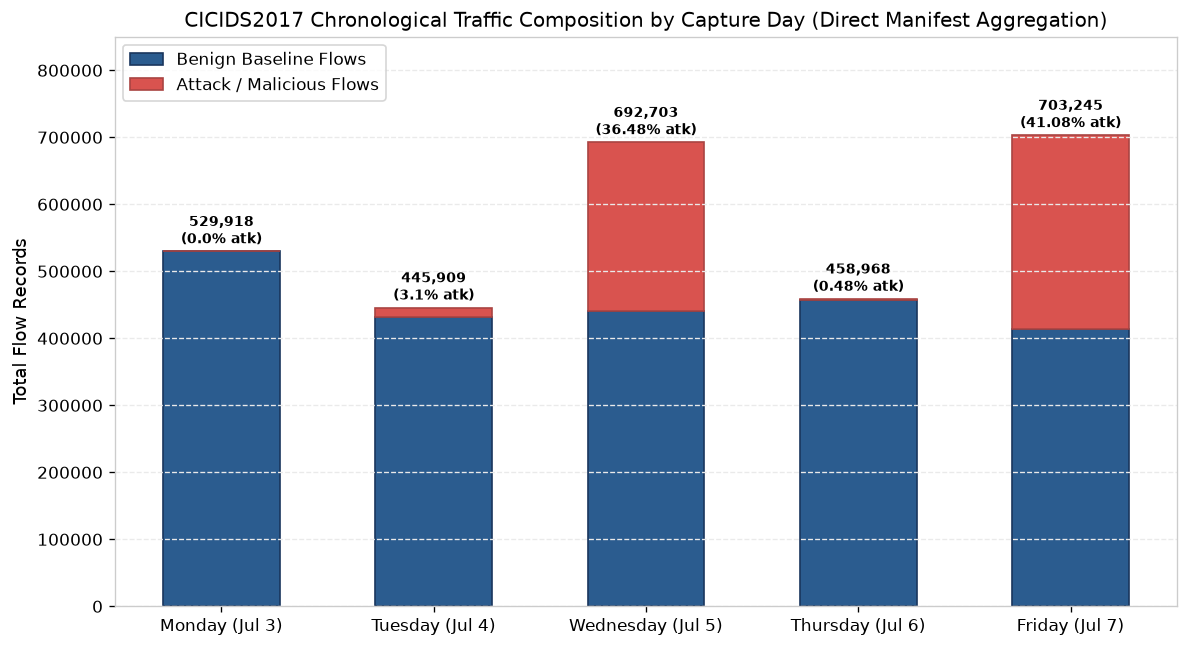

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))

days = df_days["Day"]
benign_bars = ax.bar(
    days,
    df_days["Benign"],
    label="Benign Baseline Flows",
    color="#2b5c8f",
    edgecolor="#1a365d",
    width=0.55,
)
attack_bars = ax.bar(
    days,
    df_days["Attacks"],
    bottom=df_days["Benign"],
    label="Attack / Malicious Flows",
    color="#d9534f",
    edgecolor="#a94442",
    width=0.55,
)

ax.set_ylabel("Total Flow Records")
ax.set_title(
    "CICIDS2017 Chronological Traffic Composition by Capture Day (Direct Manifest Aggregation)"
)
ax.grid(True, axis="y")
ax.legend(frameon=True)

# Add annotations
for i, row in df_days.iterrows():
    tot = row["Rows"]
    atk_pct = row["Attack %"]
    ax.text(
        i,
        tot + 12000,
        f"{tot:,}" + "\n" + f"({atk_pct}% atk)",
        ha="center",
        fontsize=8.5,
        weight="bold",
    )

ax.set_ylim(0, 850_000)
plt.tight_layout()
plt.show()

### Critical Protocol Decision: Why Tuesday Cannot Be Split Mid-Day
In some naive ML experiments, Tuesday is split 50/50 for training and validation.
Our Phase 2 forensic audit demonstrated why this is scientifically invalid:
1. **Lack of Per-Flow Timestamps:** Splitting halfway through `Tuesday-WorkingHours.pcap_ISCX.csv` cannot guarantee a chronological boundary.
2. **Early Contamination:** In the UNB testbed schedule, FTP-Patator attacks began at 09:20 AM (within 25 minutes of network start). An arbitrary slice will contaminate the training partition with attack records.
3. **The Clean Monday Alternative:** Monday provides **529,918 completely uncontaminated benign flows**. Using Monday exclusively as the one-class anomaly baseline guarantees **100% pure benign fitting** with zero attack leakage.


## 4. Benchmark v1 Partition Allocation

In Phase 3.2, NETDEFY constructed an official reproducible **200,000-record experimental benchmark** (`data/benchmark/v1/`) plus a **6,193-record supplementary diagnostic dataset**.
This benchmark preserves the statistical distribution, temporal ordering, and rare-attack diversity of the full 2.83M dataset while enabling rapid, memory-safe experimentation.

We inspect the partition sizes and sources directly from `data/benchmark/v1/metadata/benchmark_manifest.json`.


In [8]:
manifest_path = benchmark_dir / "metadata" / "benchmark_manifest.json"
with open(manifest_path) as f:
    manifest = json.load(f)

part_info = []
for part_name, meta in manifest["files"].items():
    part_info.append(
        {
            "Partition": part_name,
            "Records": meta["records"],
            "Size (MB)": meta["size_mb"],
            "Path": meta["path"],
            "SHA-256": meta["sha256"][:12] + "...",
        }
    )

df_part = pd.DataFrame(part_info)
print(f"Total Benchmark Records: {manifest['total_benchmark_records']:,}")
print(df_part.to_string(index=False))

Total Benchmark Records: 200,000
            Partition  Records  Size (MB)                                                          Path         SHA-256
       oneclass_train   100000      10.36                      data/benchmark/v1/oneclass_train.parquet 06157578c424...
     classifier_train    30000       3.07                    data/benchmark/v1/classifier_train.parquet d5d69f75f446...
           validation    20000       2.11                          data/benchmark/v1/validation.parquet 3116213f1a94...
                 test    50000       4.44                                data/benchmark/v1/test.parquet 263437c2e7da...
rare_class_diagnostic     6193       0.56 data/benchmark/v1/supplementary/rare_class_diagnostic.parquet 4eb33a3d3b28...


<string>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


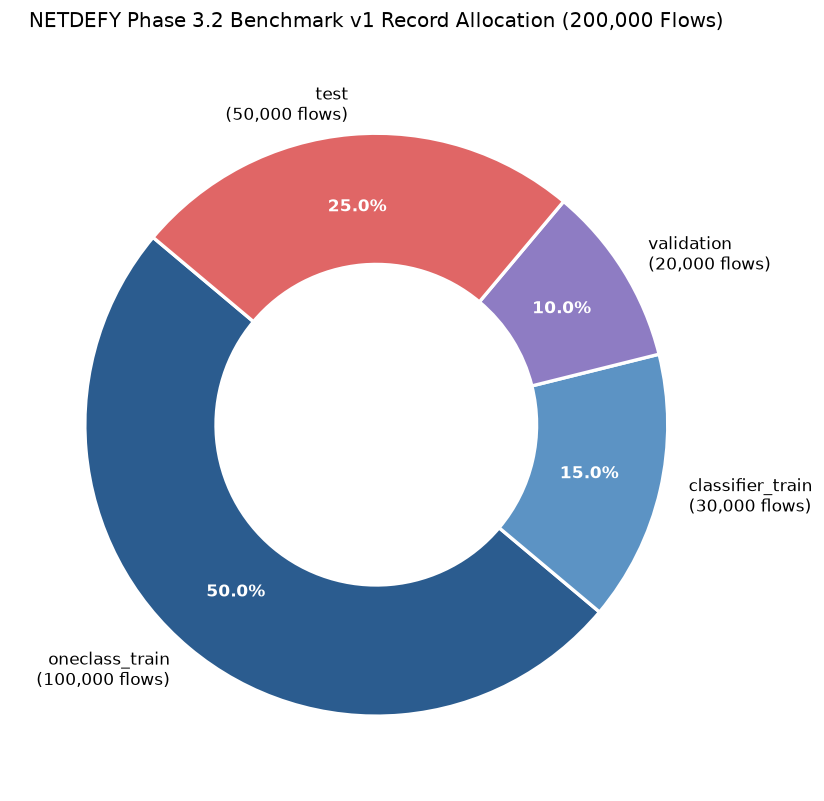

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))

df_core = df_part[df_part["Partition"] != "rare_class_diagnostic"]
sizes = df_core["Records"]
labels = [
    f"{row['Partition']}" + "\n" + f"({row['Records']:,} flows)" for _, row in df_core.iterrows()
]
colors = ["#2b5c8f", "#5c93c4", "#8e7cc3", "#e06666"]

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    pctdistance=0.75,
    colors=colors,
    startangle=140,
    wedgeprops={"width": 0.45, "edgecolor": "#ffffff", "linewidth": 2},
)

for autotext in autotexts:
    autotext.set_color("#ffffff")
    autotext.set_weight("bold")

ax.set_title("NETDEFY Phase 3.2 Benchmark v1 Record Allocation (200,000 Flows)", pad=20)
plt.tight_layout()
plt.show()

## 5. Research Limitations & Key Invariants

1. **Chronological Holdout Purity:** Monday flows (`oneclass_train.parquet`) contain **0 attack flows**, establishing a verifiable attack-free baseline for Phase 4A/4B one-class engines.
2. **Disjoint Midweek Records:** Sourced from Tuesday and Wednesday, `classifier_train.parquet` (30k rows) and `validation.parquet` (20k rows) share **exactly 0 raw records**, preventing memorization leakage during model selection.
3. **Temporal Generalization Testbed:** `test.parquet` (50,000 flows) is drawn strictly from Thursday and Friday. 100% of the attack categories in Thursday/Friday (`PortScan`, `DDoS`, `Bot`, `Infiltration`, `Web Attacks`) were completely unobserved in Tuesday/Wednesday training, creating a genuine zero-day evaluation challenge.
